# `FrozenEstimator` examples: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/frozen/plot_frozen_examples.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
(<https://scikit-learn.org/dev/auto_examples/frozen/plot_frozen_examples.html>).

**Scenario:** fit a classifier once, wrap it in `FrozenEstimator`, then (a) give it a custom decision
threshold through `FixedThresholdClassifier` and (b) calibrate it with `CalibratedClassifierCV` without
refitting the base model; the example reports Brier scores before and after calibration.
A third section (not in the example, but the use case its docstring names) puts a frozen fitted
`StandardScaler` inside a `Pipeline`.

**Adaptations:**

- The official cells run unchanged with `LogisticRegression`. Moxie has no `LogisticRegression`
  (owner: `linear_model`), so the Moxie scenario and its sklearn counterpart use
  `LinearDiscriminantAnalysis` (default `solver="svd"`): a linear probabilistic classifier with
  `predict_proba` and `decision_function`, like the original. Data: the example's
  `make_classification(n_samples=1000, random_state=0)` and `train_test_split(random_state=0)`,
  generated in Python and shared as `.npy` files; labels are `List[Int]`.
- `FixedThresholdClassifier` is an API scaffold in `moxie.model_selection`; it is recorded as a GAP
  and an `--expect-fail` cell shows its clear `NotImplementedError`.
- Moxie's `CalibratedClassifierCV` consumes a `CalibrationEstimator` adapter
  (`docs/calibration/family.md`): the Mojo cell defines a small LDA adapter (the same shape as
  `tests/calibration/test_public.mojo`) and freezes it with
  `FrozenCalibrationEstimator(FrozenEstimator(adapter^))`. Targets are Float64 arrays there.
- `brier_score_loss` is computed in Python from each side's probabilities (Moxie has no `metrics`
  module); it is a scoring step, not learning.

**Determinism:** fully deterministic (fixed seeds, closed-form LDA, deterministic calibration);
predictions and probabilities are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("frozen/plot_frozen_examples")

## 1. scikit-learn: the official example (unchanged)

In [2]:
from sklearn.datasets import make_classification
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import FixedThresholdClassifier, train_test_split

X, y = make_classification(n_samples=1000, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
classifier = LogisticRegression().fit(X_train, y_train)

print(
    "Probability estimates for three data points:\n"
    f"{classifier.predict_proba(X_test[-3:]).round(3)}"
)
print(
    "Predicted class for the same three data points:\n"
    f"{classifier.predict(X_test[-3:])}"
)

threshold_classifier = FixedThresholdClassifier(
    estimator=FrozenEstimator(classifier), threshold=0.9
)
print(
    "Probability estimates for three data points with FixedThresholdClassifier:\n"
    f"{threshold_classifier.predict_proba(X_test[-3:]).round(3)}"
)
print(
    "Predicted class for the same three data points with FixedThresholdClassifier:\n"
    f"{threshold_classifier.predict(X_test[-3:])}"
)

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

calibrated_classifier = CalibratedClassifierCV(
    estimator=FrozenEstimator(classifier)
).fit(X_train, y_train)

prob_pos_clf = classifier.predict_proba(X_test)[:, 1]
clf_score = brier_score_loss(y_test, prob_pos_clf)
print(f"No calibration: {clf_score:.3f}")

prob_pos_calibrated = calibrated_classifier.predict_proba(X_test)[:, 1]
calibrated_score = brier_score_loss(y_test, prob_pos_calibrated)
print(f"With calibration: {calibrated_score:.3f}")

Probability estimates for three data points:
[[0.18 0.82]
 [0.29 0.71]
 [0.   1.  ]]
Predicted class for the same three data points:
[1 1 1]
Probability estimates for three data points with FixedThresholdClassifier:
[[0.18 0.82]
 [0.29 0.71]
 [0.   1.  ]]
Predicted class for the same three data points with FixedThresholdClassifier:
[0 0 1]
No calibration: 0.033
With calibration: 0.032


## 2. scikit-learn: the same scenario with the substituted classifier

`LinearDiscriminantAnalysis` replaces `LogisticRegression`. Everything else follows the example; the
pipeline section fits a `StandardScaler` on the training split, freezes it, and fits
`make_pipeline(FrozenEstimator(scaler), LinearDiscriminantAnalysis())` on a shifted copy of the
test split so that a refit scaler would give different statistics.

In [3]:
import numpy as np
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
frozen = FrozenEstimator(lda)
frozen.fit(X_test, 1 - y_test)  # no-op: the wrapped model is not refit
sk = {
    "proba": frozen.predict_proba(X_test),
    "pred": frozen.predict(X_test).astype(float),
    "decision": frozen.decision_function(X_test),
    "clone_proba": clone(frozen).predict_proba(X_test),
    "coef": frozen.coef_,
    "intercept": frozen.intercept_,
    "classes": frozen.classes_.astype(float),
    "score": np.array([frozen.score(X_test, y_test)]),
}
manual_threshold = (sk["proba"][:, 1] >= 0.9).astype(float)  # what FixedThresholdClassifier(0.9) predicts
print("LDA probabilities for the last three test points:\n", sk["proba"][-3:].round(3))
print("predicted:", sk["pred"][-3:], " threshold 0.9:", manual_threshold[-3:])

sk_cal = CalibratedClassifierCV(estimator=FrozenEstimator(lda)).fit(X_train, y_train)
sk["cal_proba"] = sk_cal.predict_proba(X_test)
sk["cal_pred"] = sk_cal.predict(X_test).astype(float)
sk["cal_a_b"] = np.array([sk_cal.calibrated_classifiers_[0].calibrators[0].a_,
                          sk_cal.calibrated_classifiers_[0].calibrators[0].b_])
print("calibrated_classifiers_:", len(sk_cal.calibrated_classifiers_),
      " base estimator is the frozen LDA:", sk_cal.calibrated_classifiers_[0].estimator.estimator is lda)
print(f"No calibration: {brier_score_loss(y_test, sk['proba'][:, 1]):.3f}")
print(f"With calibration: {brier_score_loss(y_test, sk['cal_proba'][:, 1]):.3f}")

X_shift = X_test + 3.0
scaler = StandardScaler().fit(X_train)
pipe = make_pipeline(FrozenEstimator(scaler), LinearDiscriminantAnalysis()).fit(X_shift, y_test)
sk["pipe_mean"] = pipe[0].mean_
sk["pipe_proba"] = pipe.predict_proba(X_shift)
sk["pipe_clone_proba"] = clone(pipe).fit(X_shift, y_test).predict_proba(X_shift)
names = [f"f{i}" for i in range(X.shape[1])]
print("feature names through the frozen scaler:", list(pipe[0].get_feature_names_out(names))[:4], "...")
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, X_shift=X_shift)

LDA probabilities for the last three test points:
 [[0.378 0.622]
 [0.182 0.818]
 [0.001 0.999]]
predicted: [1. 1. 1.]  threshold 0.9: [0. 0. 1.]
calibrated_classifiers_: 1  base estimator is the frozen LDA: True
No calibration: 0.034
With calibration: 0.034
feature names through the frozen scaler: ['f0', 'f1', 'f2', 'f3'] ...


## 3. Moxie (native Mojo)

The same scenario through Moxie's public API: `moxie.frozen.FrozenEstimator`,
`moxie.discriminant_analysis.LinearDiscriminantAnalysis`, `moxie.calibration.CalibratedClassifierCV`,
`moxie.preprocessing.StandardScaler` and `moxie.pipeline.make_pipeline`.

In [4]:
%%mojo frozen_examples
import numojo as nm
from std.memory import ArcPointer
from moxie.base import clone
from moxie.frozen import FrozenEstimator
from moxie.discriminant_analysis import LinearDiscriminantAnalysis
from moxie.calibration import CalibrationEstimator, CalibratedClassifierCV, FrozenCalibrationEstimator
from moxie.preprocessing import StandardScaler
from moxie.pipeline import make_pipeline
from moxie_nb_io import load, load_ints, save, save_floats, save_ints, save_strings

comptime LDA = LinearDiscriminantAnalysis[DType.float64, Int]
comptime Array = nm.NDArray[DType.float64]


struct LDAAdapter(CalibrationEstimator):
    """Calibration adapter (docs/calibration/family.md): Float64 targets, decision responses."""
    comptime Params = LDA.Params
    var model: ArcPointer[LDA]

    def __init__(out self) raises:
        self.model = ArcPointer(LDA())

    def get_params(self, deep: Bool = True) raises -> Self.Params:
        return self.model[].get_params(deep)

    def set_params[origin: MutOrigin, params_origin: ImmOrigin](
        ref[origin] self, ref[params_origin] params: Self.Params
    ) raises -> ref[self] Self:
        var model = self.model[].__sklearn_clone__()
        _ = model.set_params(params)
        self.model = ArcPointer(model^)
        return self

    def __sklearn_clone__(self) raises -> Self:
        var result = Self()
        result.model = ArcPointer(self.model[].__sklearn_clone__())
        return result^

    def __sklearn_is_fitted__(self) -> Bool:
        return self.model[].__sklearn_is_fitted__()

    def fit(mut self, X: Array, y: Array, sample_weight: Optional[Array] = None) raises:
        if sample_weight:
            raise Error("ValueError: LDA does not support weighted fitting")
        var labels = List[Int]()
        for i in range(y.size):
            labels.append(Int(y.item(i)))
        var model = self.model[].__sklearn_clone__()
        _ = model.fit(X, labels)
        self.model = ArcPointer(model^)

    def class_labels(self) raises -> Array:
        var result = nm.zeros[DType.float64](nm.Shape(len(self.model[].classes_)))
        for i in range(len(self.model[].classes_)):
            result[nm.Item(i)] = Float64(self.model[].classes_[i])
        return result^

    def uses_probabilities(self) -> Bool:
        return False

    def response(self, X: Array) raises -> Array:
        var response = self.model[].decision_function(X)
        if response.ndim == 1:
            return response.reshape(nm.Shape(response.size, 1))
        return response^


def as_array(y: List[Int]) raises -> Array:
    var out = Array(nm.Shape(len(y)))
    for i in range(len(y)):
        out[nm.Item(i)] = Float64(y[i])
    return out^


def main() raises:
    var X_train = load("X_train")
    var y_train = load_ints("y_train")
    var X_test = load("X_test")
    var y_test = load_ints("y_test")
    var X_shift = load("X_shift")

    # Frozen classifier: fit is a no-op, inference and clone delegate to the fitted model.
    var lda = LDA()
    _ = lda.fit(X_train, y_train)
    var frozen = FrozenEstimator(lda^)
    var flipped = List[Int]()
    for v in y_test:
        flipped.append(1 - v)
    _ = frozen.fit(X_test, flipped)
    save("proba", frozen.predict_proba(X_test))
    save_ints("pred", frozen.predict(X_test))
    save("decision", frozen.decision_function(X_test))
    save("clone_proba", clone(frozen).predict_proba(X_test))
    save("coef", frozen.estimator().coef_)
    save("intercept", frozen.estimator().intercept_)
    save_ints("classes", frozen.estimator().classes_)
    save_floats("score", [frozen.score(X_test, y_test)])

    # Calibration of the pre-fitted classifier (ensemble="auto" -> one pooled calibrator).
    var base = LDAAdapter()
    base.fit(X_train, as_array(y_train))
    var calibrated = CalibratedClassifierCV(FrozenCalibrationEstimator(FrozenEstimator(base^)))
    _ = calibrated.fit(X_train, as_array(y_train))
    save("cal_proba", calibrated.predict_proba(X_test))
    save("cal_pred", calibrated.predict(X_test))
    print("calibrated_classifiers_:", len(calibrated.calibrated_classifiers_))

    # Frozen fitted scaler inside a pipeline: Pipeline.fit leaves its statistics untouched.
    var scaler = StandardScaler()
    _ = scaler.fit(X_train)
    var pipe = make_pipeline(FrozenEstimator(scaler^), LDA())
    _ = pipe.fit(X_shift, y_test)
    save("pipe_mean", pipe.transformer.estimator().mean_.value())
    save("pipe_proba", pipe.predict_proba(X_shift))
    var fresh = clone(pipe)
    _ = fresh.fit(X_shift, y_test)
    save("pipe_clone_proba", fresh.predict_proba(X_shift))
    var names = List[String]()
    for i in range(X_train.shape[1]):
        names.append("f" + String(i))
    save_strings("names", pipe.transformer.get_feature_names_out(names^))
    print("pipeline steps:", pipe.transformer_name, pipe.estimator_name)

calibrated_classifiers_: 1
pipeline steps: frozenestimator lineardiscriminantanalysis


In [5]:
%%mojo fixed_threshold --expect-fail
from moxie.frozen import FrozenEstimator
from moxie.discriminant_analysis import LinearDiscriminantAnalysis
from moxie.model_selection import FixedThresholdClassifier


def main() raises:
    var model = FrozenEstimator(LinearDiscriminantAnalysis[DType.float64, Int]())
    var threshold = FixedThresholdClassifier(model^, threshold=0.9)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: FixedThresholdClassifier.__init__ is an API scaffold



## 4. Side by side and parity

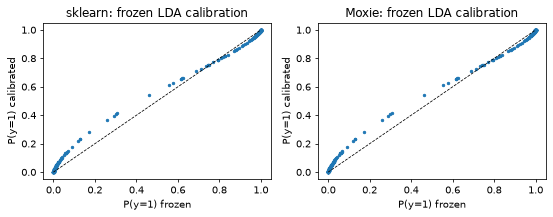

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
frozen classes_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
frozen predict (after no-op fit on flipped labels),PASS,"(250,)","(250,)",,,exact,0 mismatches,
frozen predict_proba,PASS,"(250, 2)","(250, 2)",3.7e-13,5.04e-11,"rtol=0, atol=1e-08",,discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic
frozen decision_function,PASS,"(250,)","(250,)",1.43e-12,8.68e-12,"rtol=1e-08, atol=1e-08",,discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic
clone(frozen).predict_proba keeps fitted state,PASS,"(250, 2)","(250, 2)",3.7e-13,5.04e-11,"rtol=0, atol=1e-08",,discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic
frozen estimator coef_,PASS,"(1, 20)","(1, 20)",2.55e-14,4.38e-13,"rtol=1e-08, atol=1e-08",,discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic
frozen estimator intercept_,PASS,"(1,)","(1,)",1.28e-12,3.05e-11,"rtol=1e-08, atol=1e-08",,discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic
frozen score (accuracy),PASS,"(1,)","(1,)",,,exact,0 mismatches,
CalibratedClassifierCV(frozen) predict,PASS,"(250,)","(250,)",,,exact,0 mismatches,
CalibratedClassifierCV(frozen) predict_proba,PASS,"(250, 2)","(250, 2)",2.23e-12,6.65e-11,"rtol=5e-06, atol=5e-06",,calibration family bound (docs/calibration/family.md): Newton vs L-BFGS sigmoid fits with different stopping criteria


In [6]:
import matplotlib.pyplot as plt
mx = nb.results["frozen_examples"]
moxie_nb.side_by_side(sklearn=sk["proba"][-3:].round(3), moxie=mx["proba"][-3:].round(3))
moxie_nb.side_by_side(
    sklearn={"brier (no calibration)": round(brier_score_loss(y_test, sk["proba"][:, 1]), 6),
             "brier (calibrated)": round(brier_score_loss(y_test, sk["cal_proba"][:, 1]), 6)},
    moxie={"brier (no calibration)": round(brier_score_loss(y_test, mx["proba"][:, 1]), 6),
           "brier (calibrated)": round(brier_score_loss(y_test, mx["cal_proba"][:, 1]), 6)})

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), dpi=70)
for ax, side, data in [(axes[0], "sklearn", sk), (axes[1], "Moxie", mx)]:
    ax.scatter(data["proba"][:, 1], data["cal_proba"][:, 1], s=6)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set(title=f"{side}: frozen LDA calibration", xlabel="P(y=1) frozen", ylabel="P(y=1) calibrated")
fig.tight_layout()
plt.show()

lda_reason = ("discriminant_analysis Float64 parity bound (docs/discriminant_analysis/scope.md): SVD solver "
              "via Jacobi vs LAPACK and summation order; FrozenEstimator itself adds no arithmetic")
nb.compare("frozen classes_", sk["classes"], mx["classes"].astype(float), exact=True)
nb.compare("frozen predict (after no-op fit on flipped labels)", sk["pred"], mx["pred"].astype(float), exact=True)
nb.compare("frozen predict_proba", sk["proba"], mx["proba"], rtol=0, atol=1e-8, reason=lda_reason)
nb.compare("frozen decision_function", sk["decision"], mx["decision"], rtol=1e-8, atol=1e-8, reason=lda_reason)
nb.compare("clone(frozen).predict_proba keeps fitted state", sk["clone_proba"], mx["clone_proba"],
           rtol=0, atol=1e-8, reason=lda_reason)
nb.compare("frozen estimator coef_", sk["coef"], mx["coef"], rtol=1e-8, atol=1e-8, reason=lda_reason)
nb.compare("frozen estimator intercept_", sk["intercept"], mx["intercept"], rtol=1e-8, atol=1e-8, reason=lda_reason)
nb.compare("frozen score (accuracy)", sk["score"], mx["score"], exact=True)
nb.compare("CalibratedClassifierCV(frozen) predict", sk["cal_pred"], mx["cal_pred"], exact=True)
nb.compare("CalibratedClassifierCV(frozen) predict_proba", sk["cal_proba"], mx["cal_proba"], rtol=5e-6, atol=5e-6,
           reason="calibration family bound (docs/calibration/family.md): Newton vs L-BFGS sigmoid fits with "
                  "different stopping criteria")
nb.compare("pipeline: frozen scaler mean_ unchanged by Pipeline.fit", sk["pipe_mean"], mx["pipe_mean"],
           rtol=1e-12, atol=1e-12, reason="Float64 mean reduction order")
nb.compare("pipeline: predict_proba", sk["pipe_proba"], mx["pipe_proba"], rtol=0, atol=1e-8, reason=lda_reason)
nb.compare("pipeline clone + refit keeps the frozen step", sk["pipe_clone_proba"], mx["pipe_clone_proba"],
           rtol=0, atol=1e-8, reason=lda_reason)
nb.compare("frozen scaler get_feature_names_out", np.array(names), np.array(mx["names"]), exact=True)
nb.note("LogisticRegression", "GAP", "moxie.linear_model has no LogisticRegression; the Moxie scenario uses "
        "LinearDiscriminantAnalysis and is compared with the same sklearn substitution (owner: linear_model).")
nb.note("FixedThresholdClassifier(FrozenEstimator(clf), threshold=0.9)", "GAP",
        "moxie.model_selection.FixedThresholdClassifier is an API scaffold whose constructor raises "
        "NotImplementedError (cell `fixed_threshold`; owner: model_selection).")
nb.note("CalibratedClassifierCV(estimator=FrozenEstimator(clf))", "ADAPTED",
        "Moxie calibration needs a CalibrationEstimator adapter and FrozenCalibrationEstimator around the "
        "FrozenEstimator (docs/calibration/family.md); no production classifier implements the adapter directly.")
nb.note("brier_score_loss", "GAP", "no moxie.metrics; the score is computed in Python from each side's probabilities.")
nb.report()
nb.assert_parity()